In [1]:
#Step 1: Load the CSVs and build the database

In [2]:
import sqlite3

In [3]:
import pandas as pd

In [4]:
df_customers = pd.read_csv("Downloads/store_customers.csv")

In [5]:
df_orders = pd.read_csv("Downloads/store_orders.csv")

In [6]:
con = sqlite3.connect("store.db")

In [7]:
df_customers.to_sql("customers", con, if_exists="replace", index=False)
df_orders.to_sql("orders", con, if_exists="replace", index=False)

200

In [8]:
#Step 2: First look - Query the first 5 rows of orders

In [9]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [10]:
# Step 3 Filter and sort - Write one query returning all orders over 100 dollars, sorted by amount from highest to lowest 

In [11]:
query="""
SELECT order_id, product, amount
FROM orders
WHERE amount  > 100 
ORDER BY amount DESC"""

In [12]:
df_filtered = pd.read_sql(query, con)
df_filtered

,order_id,product,amount
0,5153,dock,499.00
1,5140,headset,295.36
2,5047,headset,293.79
3,5150,monitor,293.35
4,5014,monitor,287.83
...,...,...,...
79,5107,shelf,110.31
80,5046,shelf,108.47
81,5009,chair,107.20
82,5007,dock,103.77


In [13]:
# Step 4 Aggregate by category - One query: for each product category, the number of orders and the average amount, named with AS, sorted by average amount descending

In [14]:
query="""
SELECT category, COUNT(*) AS n, AVG(amount) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC"""

In [15]:
df_category_summary = pd.read_sql(query, con)
df_category_summary

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


In [16]:
#Mark down Cell
#Electronics on average earn the most per order at $190.57 out of all categories

In [17]:
# Step 5 - Join for spend by city - Write the JOIN (Tutorial 5 pattern): total spend per customer city, using the key the data dictionary gives you, sorted by total descending.

In [18]:
query="""
SELECT c.city, SUM(o.amount) AS total_spend
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC
"""

In [19]:
df_city_spend = pd.read_sql(query, con)
df_city_spend

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


In [20]:
# Step 6 Count the rows before and after

In [21]:
order_count = len(df_orders)
print(order_count)

200


In [22]:
joined_len = len(pd.read_sql("SELECT * FROM orders o JOIN customers c ON o.customer_id = c.customer_id", con))
print(joined_len)

195


In [23]:
# There are 5 customer_id that match no customers because during the join, it tries to look for the matching customer_id for orders and customers.  Since there are 5 that don't match up, the join drops those 5 since there are no matching having the differnce of 200-195 for the the total of 5 missing customers.

In [24]:
#Step 7 - chart a query result

In [25]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'Total Spend ($)')

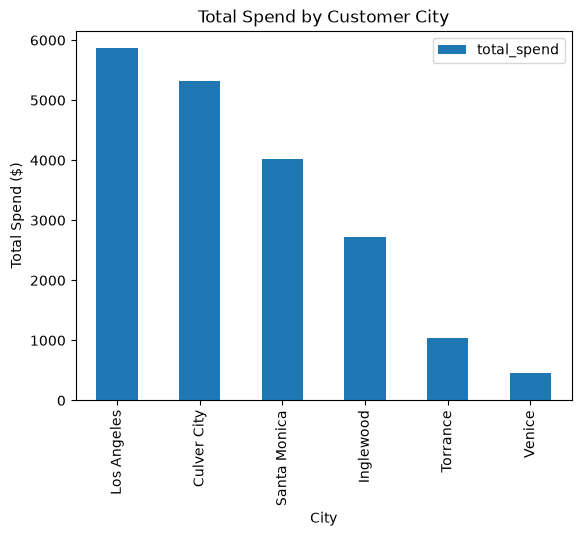

In [26]:
df_city_spend.plot(
    kind="bar", 
    x="city", 
    y="total_spend")
plt.title("Total Spend by Customer City")
plt.xlabel("City")
plt.ylabel("Total Spend ($)")

In [27]:
#Step 8 - Your own question
# Breaking down Los Angeles total spending, how much was spent in each category?

In [28]:
query = """
SELECT o.category, SUM(o.amount) AS total_spend, COUNT(o.order_id) AS order_count
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE c.city = 'Los Angeles'
GROUP BY o.category
ORDER BY total_spend DESC
"""

df_la_categories = pd.read_sql(query, con)
df_la_categories

,category,total_spend,order_count
0,electronics,3527.42,16
1,furniture,1929.67,14
2,office,304.96,10
3,snacks,100.94,6


In [29]:
#Los Angeles total spends show the least spent on snacks and the most on electronics.

In [30]:
#Step 9 - Ethics
# To protect customers information, any personally identifiable information like individual customer names would either have to be removed or not have the raw data accessible for the general public data push. This prevents the exposure of personal information and ensures compliance with ethics.